# M303 - Visualización de datos

> Módulo III - Python para la inteligencia artificial
>
> Tema 3: Visualización de datos (Matplotlib, Seaborn)

Contenido:

1. Análisis Individual para Características Continuas
2. Análisis Individual para Características Discretas
3. Selección de la Respuesta
4. Discretización
5. Cuantización
6. Análisis Cruzado de las Características Contra la Respuesta

In [17]:
import pandas as pd
import numpy as np
from matplotlib import pyplot
import seaborn

In [2]:
titanic = pd.read_csv("../conjuntos/titanic.csv")

titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
# Cascada de relevancia en la información del conjunto de datos que es analizable
# Seleccionamos la información que muestra las características para el análisis
# Se reorganiza por relevancia

titanic[["Survived", "Sex", "Pclass", "Fare", "Cabin", "Embarked", "Age", "Parch"]].head() 

,Survived,Sex,Pclass,Fare,Cabin,Embarked,Age,Parch
0,0,male,3,7.2500,NaN,S,22.0,0
1,1,female,1,71.2833,C85,C,38.0,0
2,1,female,3,7.9250,NaN,S,26.0,0
3,1,female,1,53.1000,C123,S,35.0,0
4,0,male,3,8.0500,NaN,S,35.0,0


In [7]:
# Naturaleza | Codificación | Tipo
# Cuantitativa/Cualitativa | Numérica/Categórica | Continua/Discreta

c1 = titanic["Survived"].map({
    0: "no",
    1: "yes"
}) # Cualitativa | Numérica (Se mapea a categórica yes/no) | Discreta
c2 = titanic["Sex"] # Cuantitiva | C | D
c3 = titanic["Pclass"].map({
    1: "1st",
    2: "2nd",
    3: "3rd"
}) # Cuantitativa | N | D
c4 = titanic["Fare"] # Cuantitativa | N | C
c5 = (~(titanic["Cabin"].isna())).map({
    True: "yes",
    False: "no"
}) # Cualitativa | C | D
c6 = titanic["Embarked"].map({
    "S": "southampton",
    "C": "cherbug",
    "Q": "queenstown",
}) # Cualitativa | Categórica | Discreta {S, C, Q} -> {southampton, cherbug, queenstown}
c7 = titanic["Age"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta 
#                                               (discreto ordenado con muchas clases)
c8 = titanic["SibSp"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta 
c9 = titanic["Parch"] # Cuantitativo | Numérica | Continua -> Semicontinua/Semidescreta

## 1. Análisis Individual para Características Continuas

In [9]:
pd.DataFrame([c4, c7, c8, c9]).T.describe() 

# Solo creer a los datos si la densidad muestra un solo cúmulo (o pico en forma de montaña)
# y si la distribución es normal (creer en el promedio y la desviación)

,Fare,Age,SibSp,Parch
count,891.000000,714.000000,891.000000,891.000000
mean,32.204208,29.699118,0.523008,0.381594
std,49.693429,14.526497,1.102743,0.806057
min,0.000000,0.420000,0.000000,0.000000
25%,7.910400,20.125000,0.000000,0.000000
50%,14.454200,28.000000,0.000000,0.000000
75%,31.000000,38.000000,1.000000,0.000000
max,512.329200,80.000000,8.000000,6.000000


(0.0, 600.0)

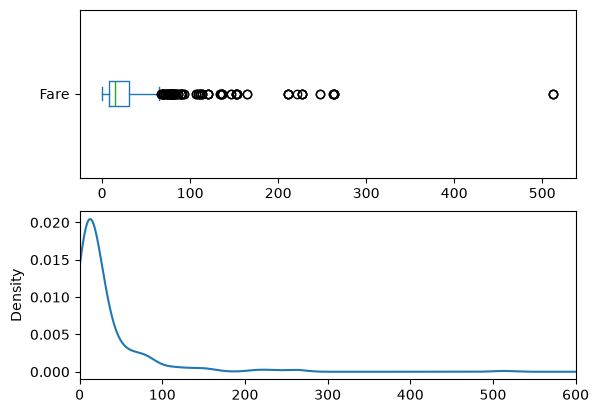

In [12]:
figure, (ax1, ax2) = pyplot.subplots(2, 1)

c4.plot.box(vert=False, ax=ax1)
c4.plot.density(ax=ax2)

pyplot.xlim((0, 600))

(0.0, 80.0)

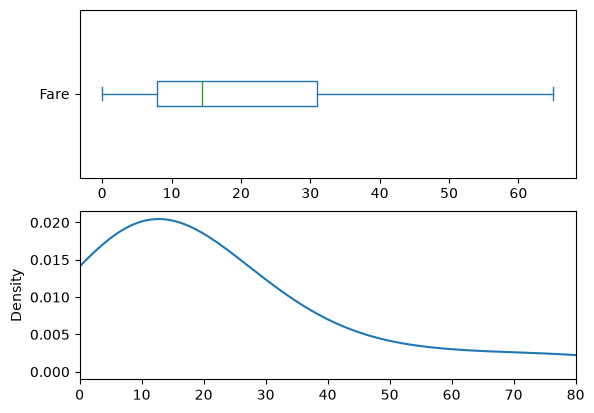

In [15]:
figure, (ax1, ax2) = pyplot.subplots(2, 1)

c4.plot.box(vert=False, showfliers=False, ax=ax1) # Eliminando de la visualización los puntos atípicos
c4.plot.density(ax=ax2)

pyplot.xlim((0, 80)) # Corrigiendo a 80, según los puntos atípicos eliminados

In [26]:
p = np.linspace(0, 100, 891) # 891 observaciones distribuidas en 100%

c4_percentil = pd.DataFrame({
    "Percentil": p,
    "Fare": c4.sort_values(),
}).reset_index().drop("index", axis=1)

c4_percentil

,Percentil,Fare
0,0.000000,0.0000
1,0.112360,0.0000
2,0.224719,0.0000
3,0.337079,0.0000
4,0.449438,0.0000
...,...,...
886,99.550562,263.0000
887,99.662921,263.0000
888,99.775281,512.3292
889,99.887640,512.3292


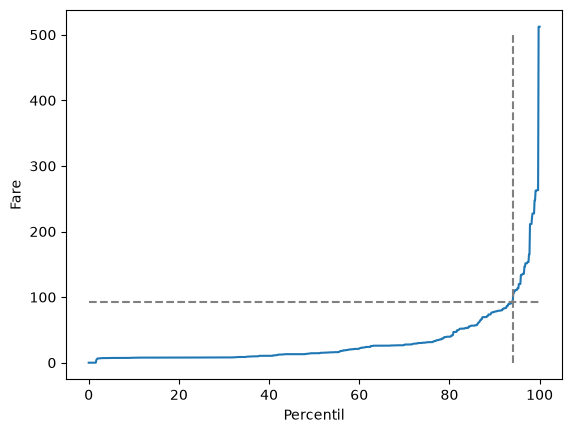

In [21]:
seaborn.lineplot(x = c4_percentil["Percentil"], y = c4_percentil["Fare"]) # Visualizar cómo aumenta la tarifa según la población
# Se observa que menos de un 10% de la población pagó mas de 100lb
# Se crean lineas de visualización para aproximar una hipótesis visual
pyplot.vlines(94, 0, 500, color="gray", linestyle="--") # Corte atípico (percentil %)
pyplot.hlines(92, 0, 100, color="gray", linestyle="--") # Corte atípico (valor)

# Hipótesis visual: 94% de los pasajeros pagaron menos de 92 libras

In [23]:
c4[c4 <= 92].count(), c4.count(), 100 * c4[c4 <= 92].count() / c4.count()
# El último valor muestra cuántos pagaron menos de 92lb, corrigiendo la hipótesis visual de 94% a 93.8%

(np.int64(836), np.int64(891), np.float64(93.82716049382717))

In [24]:
c4_percentil["P"] = c4_percentil["Percentil"].astype(int)

c4_percentil.groupby("P").mean().tail(11)

,Percentil,Fare
P,,
90,90.449438,78.500922
91,91.460674,80.153233
92,92.471910,84.232856
93,93.483146,90.429644
94,94.494382,107.520356
95,95.505618,120.791667
96,96.516854,141.337944
97,97.528090,168.432878
98,98.539326,227.750922


Text(0.5, 124.15601111111113, '114.2 (<95%)')

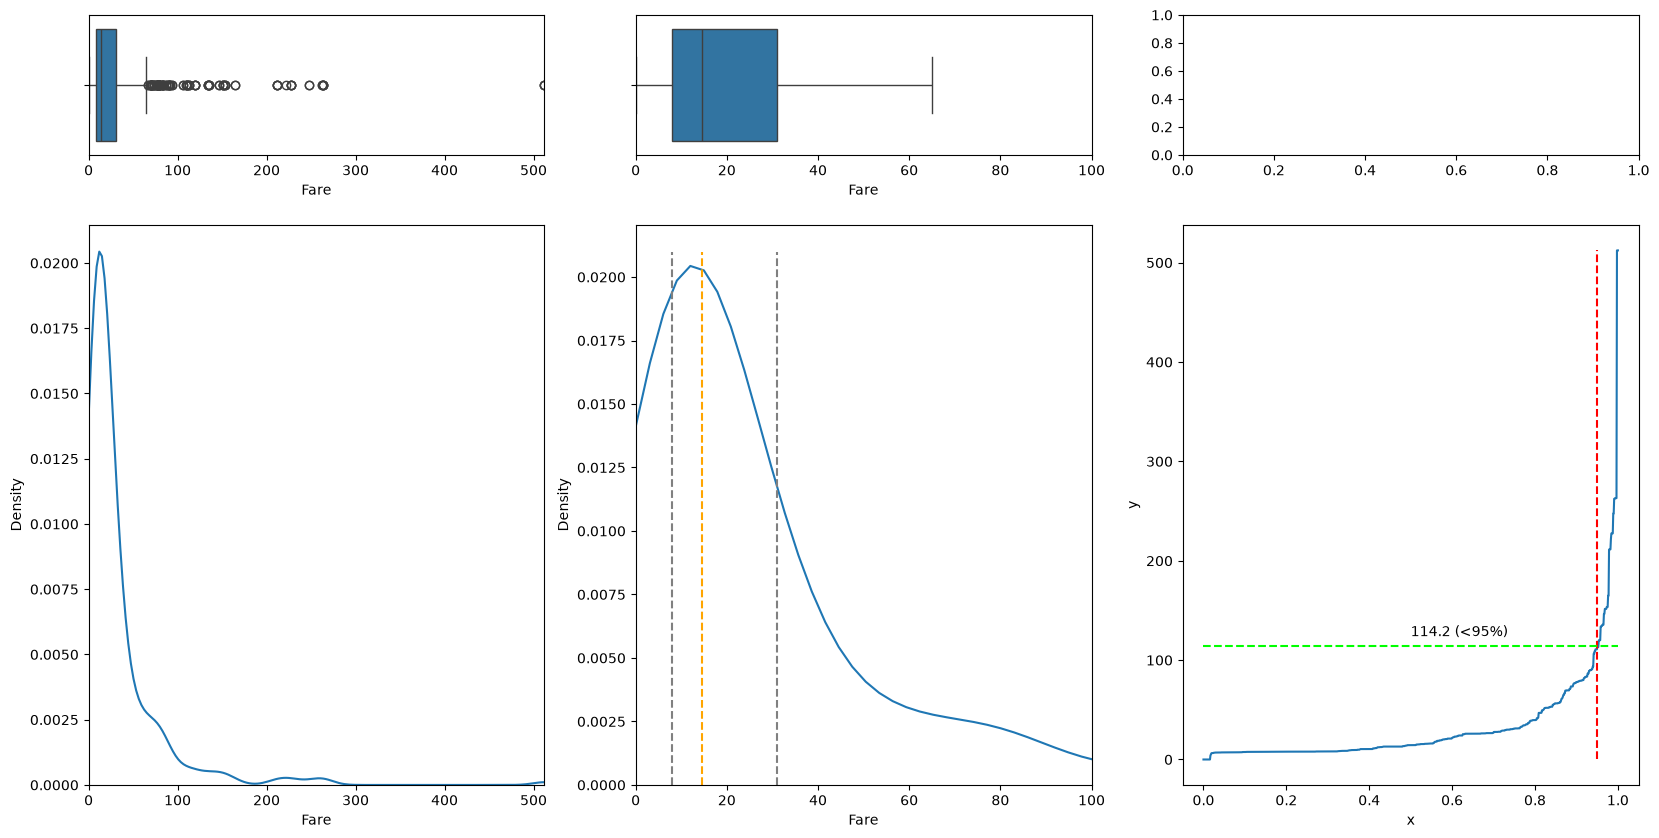

In [57]:
figure, ax = pyplot.subplots(2, 3, height_ratios = (1, 4), figsize = (20, 10)) # Crear una figura de gráficos

# Primer boxplot [0, 0] de la figura
seaborn.boxplot(x=c4, ax=ax[0, 0])
ax[0, 0].set_xlim((c4.min(), c4.max())) # Delimitador en eje x del primer box plot
# Segundo boxplot [0, 1]
seaborn.boxplot(x=c4, showfliers=False, ax=ax[0, 1])
ax[0, 1].set_xlim((0, 100)) # Delimitador en eje x

# Primer density plot [1, 0]
seaborn.kdeplot(x=c4, ax=ax[1, 0]) 
ax[1, 0].set_xlim((c4.min(), c4.max())) # Delimitador en eje x del primer density plot
# Segundo density plot [1, 1]
seaborn.kdeplot(x=c4, ax=ax[1, 1]) 
ax[1, 1].set_xlim((0, 100)) # Delimitador en eje x del segundo density plot
ax[1, 1].vlines(c4.quantile(0.25), 0, 0.021, color="gray", linestyle="--") # Cuantil 25%
ax[1, 1].vlines(c4.quantile(0.50), 0, 0.021, color="orange", linestyle="--") # Cuantil 50%
ax[1, 1].vlines(c4.quantile(0.75), 0, 0.021, color="gray", linestyle="--") # Cuantil 75%

# Tercer plot (line plot) [1, 2]
curva = pd.DataFrame({
    "x": np.linspace(0, 1, c4.size),
    "y": c4.sort_values().values
}) # Creación de un DF para facilitar la representación de los valores organizados de forma ascendente de c4 (Fare)

seaborn.lineplot(x = curva["x"], y = curva["y"], ax = ax[1, 2]) 
ax[1, 2].vlines(0.95, c4.min(), c4.max(), color="red", linestyle="--")
y_95 = curva[(curva["x"] > 0.94) & (curva["x"] < 0.96)].mean()["y"] # Máscara para representar la línea horizontal del 95% de la población (representación de y en el 95% de x)
ax[1, 2].hlines(y_95, 0, 1, color="lime", linestyle="--")
ax[1, 2].text(0.5, y_95 + 10, f"{y_95:.1f} (<95%)")